Shape: (150, 4)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


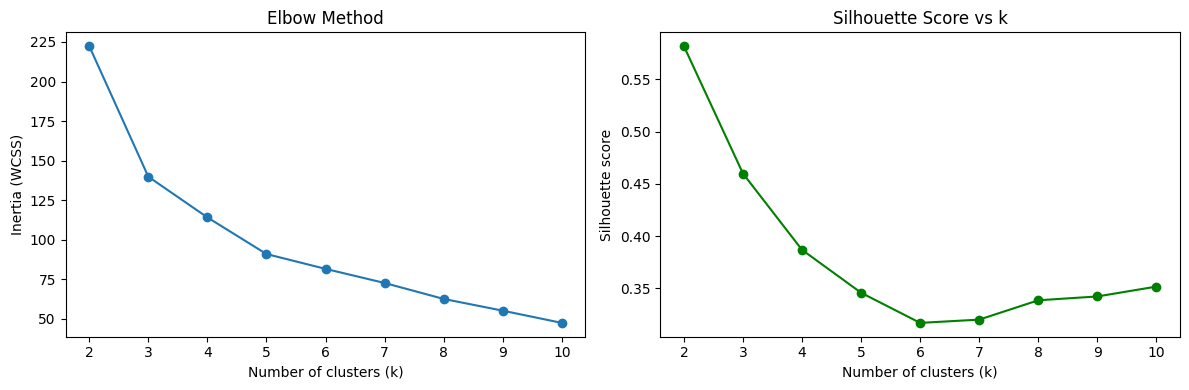


Best k by silhouette score: 2


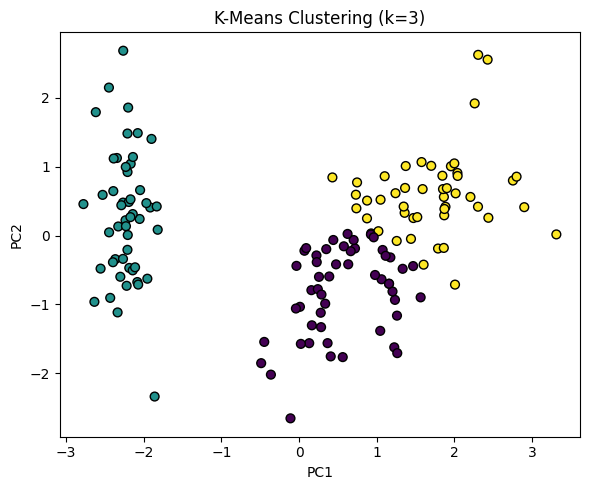

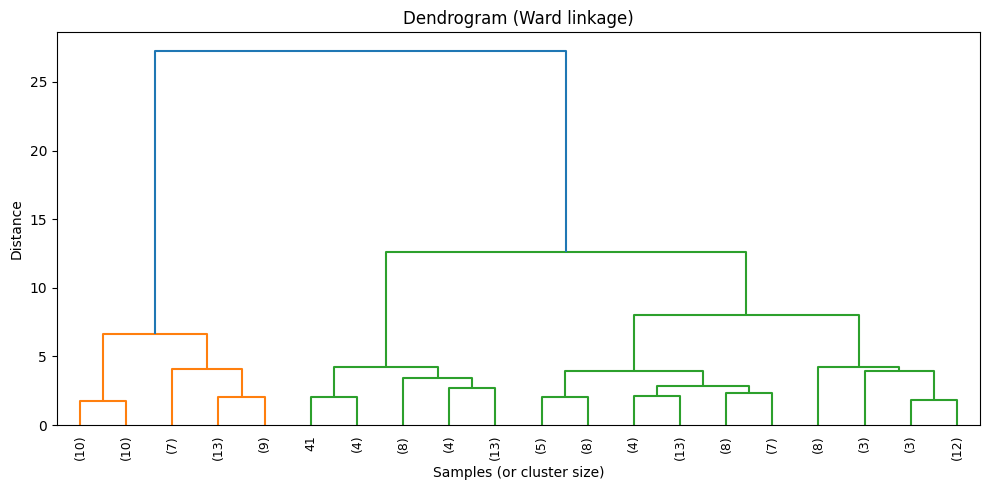

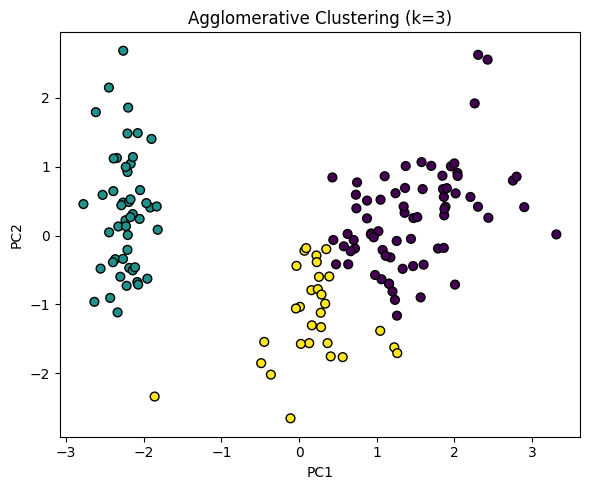


DBSCAN found 2 clusters and 4 noise points


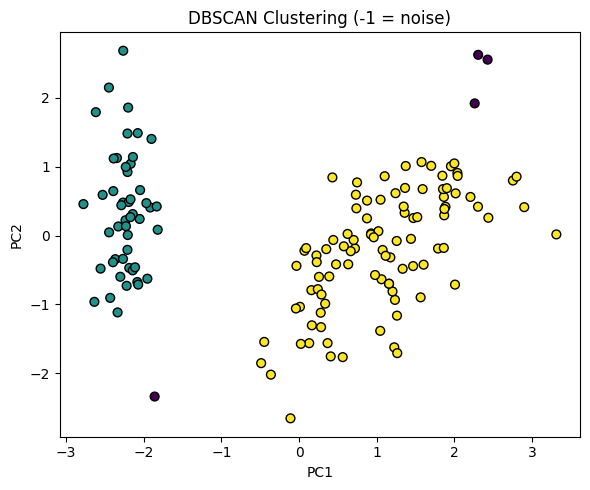


Comparison of clustering algorithms:

    Algorithm  Clusters  Silhouette  Adjusted Rand Index
      K-Means         3       0.460                0.620
Agglomerative         3       0.447                0.615
       DBSCAN         2       0.598                0.552

K-Means cluster centres (original units):
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0               5.80              2.67               4.37              1.41
1               5.01              3.43               1.46              0.25
2               6.78              3.10               5.51              1.97

Conclusion: higher silhouette = better separated clusters; Adjusted Rand Index close to 1 = clusters match the true species.


In [ ]:
"""
Assignment 2: Apply the clustering techniques using unsupervised learning.

Techniques covered:
  1. K-Means (with Elbow method and Silhouette score to choose k)
  2. Hierarchical / Agglomerative clustering (with dendrogram)
  3. DBSCAN (density based)
  4. Comparison of all three using silhouette score

Dataset: Iris (labels are NOT used for training, only to check the result).

Install: pip install pandas numpy matplotlib seaborn scipy scikit-learn
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

# ------------------------------------------------------------------
# 1. Load and scale the data (labels are ignored for clustering)
# ------------------------------------------------------------------
iris = load_iris(as_frame=True)
X = iris.data
y_true = iris.target            # only used to evaluate at the end

print("Shape:", X.shape)
print(X.head())

X_scaled = StandardScaler().fit_transform(X)

# 2D projection used only for plotting the clusters
X_2d = PCA(n_components=2, random_state=42).fit_transform(X_scaled)


def plot_clusters(labels, title):
    plt.figure(figsize=(6, 5))
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="viridis", s=40, edgecolor="k")
    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------------
# 2. K-Means: choose k using Elbow method and Silhouette score
# ------------------------------------------------------------------
inertia, sil_scores = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_range, inertia, "o-")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia (WCSS)")

ax[1].plot(k_range, sil_scores, "o-", color="green")
ax[1].set_title("Silhouette Score vs k")
ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"\nBest k by silhouette score: {best_k}")

# Final K-Means model (k=3 matches the 3 iris species, also try best_k)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X_scaled)
plot_clusters(km_labels, "K-Means Clustering (k=3)")

# ------------------------------------------------------------------
# 3. Hierarchical (Agglomerative) clustering + dendrogram
# ------------------------------------------------------------------
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90., leaf_font_size=9)
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Samples (or cluster size)")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)
plot_clusters(agg_labels, "Agglomerative Clustering (k=3)")

# ------------------------------------------------------------------
# 4. DBSCAN (no need to specify number of clusters)
# ------------------------------------------------------------------
dbscan = DBSCAN(eps=0.9, min_samples=5)
db_labels = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)
print(f"\nDBSCAN found {n_clusters_db} clusters and {n_noise} noise points")
plot_clusters(db_labels, "DBSCAN Clustering (-1 = noise)")

# ------------------------------------------------------------------
# 5. Compare the algorithms
# ------------------------------------------------------------------
def evaluate(name, labels):
    mask = labels != -1                      # ignore DBSCAN noise
    n_clusters = len(set(labels[mask]))
    sil = silhouette_score(X_scaled[mask], labels[mask]) if n_clusters > 1 else np.nan
    ari = adjusted_rand_score(y_true, labels)
    return {"Algorithm": name, "Clusters": n_clusters,
            "Silhouette": round(sil, 3), "Adjusted Rand Index": round(ari, 3)}


results = pd.DataFrame([
    evaluate("K-Means", km_labels),
    evaluate("Agglomerative", agg_labels),
    evaluate("DBSCAN", db_labels),
])
print("\nComparison of clustering algorithms:\n")
print(results.to_string(index=False))

# Cluster centres of K-Means in original feature units
centers = pd.DataFrame(
    StandardScaler().fit(X).inverse_transform(kmeans.cluster_centers_),
    columns=X.columns).round(2)
print("\nK-Means cluster centres (original units):\n", centers)

print("\nConclusion: higher silhouette = better separated clusters; "
      "Adjusted Rand Index close to 1 = clusters match the true species.")